# Where is Adelaide turning paddocks and big blocks into housing?

Two open datasets from South Australia's Department for Housing and Urban Development:

- **Land Use Generalised**, one layer a year, each parcel's land use from its valuation code, in 17 classes. Here the
  layers of 30 June 2018 and 30 June 2025 across Greater Adelaide.
- **Land Division Applications**, every proposed allotment of every land division, with its purpose, decision and dates.
  Here the allotments for homes in divisions lodged from 1 July 2018 to 30 June 2025 and approved.

Each allotment is sorted by what its land was in 2018: infill (already residential), greenfield (farmland, vacant land or
rural living), vacant urban land, or other. The shapes in `data/geometry/` were made in
[Plotlay](https://www.getplotlay.com). This notebook reads only `../data`.

In [1]:
import json, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
DATA = '../data'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
lots = pd.read_csv(f'{DATA}/tables/allotments.csv', dtype={'sa2_code': str, 'lga_code': str})
print(len(lots), 'approved residential allotments'); print(lots.kind.value_counts().to_string())

85145 approved residential allotments
kind
Greenfield                 37322
Infill                     33607
Vacant residential land     7696
Brownfield and other        6034
Not in the 2018 layer        486


## 1. Why not count parcels in the land use layer?

The layer is not one shape per parcel: neighbouring parcels of one class are drawn as one shape, and how much is merged
changed in 2017 and 2018 (the layer's own lineage: community and strata plans were handled anew). Greater Adelaide's
area in each class, year by year, shows the jumps that are about how the layer was made, not the ground.

In [2]:
yr = pd.read_csv(f'{DATA}/tables/area_by_year.csv', index_col=0)
yr.loc[['RESIDENTIAL', 'RURAL_RESID', 'RESERVE', 'NONPRIVATE_RESID', 'VACANT_RESID']].round(0)

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
c,,,,,,,,,,,
RESIDENTIAL,33481.0,33499.0,34186.0,34290.0,34383.0,34486.0,34823.0,34913.0,34945.0,35262.0,35579.0
RURAL_RESID,79930.0,80316.0,81050.0,81369.0,81416.0,81325.0,81248.0,81358.0,81170.0,81766.0,82088.0
RESERVE,21460.0,21682.0,21604.0,24659.0,25498.0,25699.0,25963.0,26797.0,22971.0,26706.0,26817.0
NONPRIVATE_RESID,650.0,675.0,845.0,693.0,1015.0,849.0,933.0,839.0,920.0,872.0,875.0
VACANT_RESID,3937.0,3869.0,4097.0,3833.0,4023.0,3918.0,4020.0,3920.0,3819.0,3799.0,3777.0


`RESERVE` drops by about 3,800 ha in 2023 and comes back in 2024; `NONPRIVATE_RESID` swings by a third from year to year.
`RESIDENTIAL` grows steadily. 2018 is used as the early year because it is the first made the way 2025 is.

## 2. Greenfield land: farm, vacant or rural living in 2018, residential in 2025

In [3]:
g = gpd.read_file(f'{DATA}/geometry/greenfield.geojson')
print(round(g.ha.sum()), 'ha in all;', round(g[g.confirmed].ha.sum()), 'ha with a residential land division over it')
g.groupby(['c2018', 'confirmed']).ha.sum().unstack().round(0)

2013 ha in all; 1101 ha with a residential land division over it


confirmed,False,True
c2018,,
AGRICULTURE,172.0,267.0
HORTICULTURE,87.0,263.0
LIVESTOCK,101.0,110.0
RURAL_RESID,351.0,405.0
VACANT,201.0,56.0


The pieces with no land division over them are mostly rural-living blocks in the Hills recoded as residential, and land
recoded after rezoning but not yet divided. They are kept apart (`recoded_ha`), not counted as built.

## 3. The allotments by kind and council

In [4]:
by = lots.pivot_table(index='lga_name', columns='kind', values='lotno', aggfunc='size', fill_value=0)
by['all'] = by.sum(axis=1)
by.sort_values('all', ascending=False).head(12)

kind,Brownfield and other,Greenfield,Infill,Not in the 2018 layer,Vacant residential land,all
lga_name,,,,,,
Playford,336,11909,1408,91,637,14381
Gawler,24,11819,788,2,1180,13813
Port Adelaide Enfield,1110,12,4750,20,1545,7437
Charles Sturt,1758,222,4529,4,812,7325
Mount Barker,48,5970,300,132,730,7180
Onkaparinga,479,1011,2567,2,927,4986
Salisbury,204,266,3110,58,481,4119
Marion,404,12,3275,105,291,4087
Light,1,3454,1,0,12,3468


## 4. Infill: what each footprint became

In [5]:
ap = pd.read_csv(f'{DATA}/tables/applications.csv')
inf = ap[ap.kind == 'Infill']
print(len(inf), 'infill applications; median allotments each', inf.lots.median())
(inf.size_band.value_counts() / len(inf) * 100).round(1)

11872 infill applications; median allotments each 2.0


size_band
2             69.4
3             16.3
4 to 9        11.4
10 or more     1.7
1              1.2
Name: count, dtype: float64

## 5. On the map

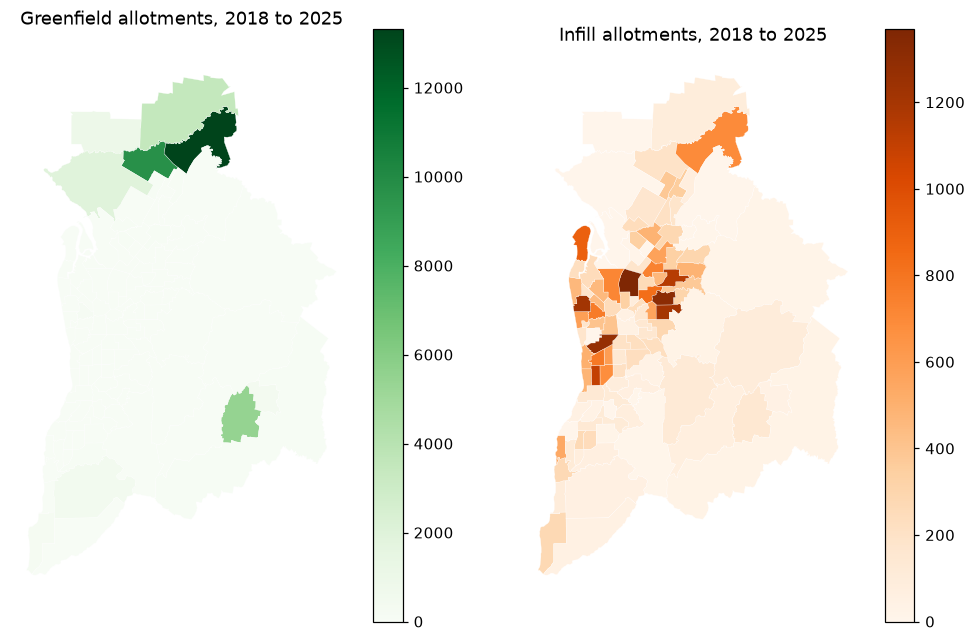

In [6]:
s = gpd.read_file(f'{DATA}/geometry/sa2.geojson')
k = lots.pivot_table(index='sa2_code', columns='kind', values='lotno', aggfunc='size', fill_value=0)
s = s.merge(k, left_on='key', right_index=True, how='left').fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 7))
for a, col, cm in zip(ax, ['Greenfield', 'Infill'], ['Greens', 'Oranges']):
    s.to_crs(9473).plot(column=col, cmap=cm, legend=True, ax=a, linewidth=0.2, edgecolor='white'); a.set_axis_off(); a.set_title(f'{col} allotments, 2018 to 2025')
plt.show()

## Read it carefully

- **Approvals, not homes.** An allotment approved is land cut for a home; it may not be built yet, and one allotment can
  hold more than one dwelling. Apartments in one building are not land divisions and do not show here.
- **Two planning laws.** Applications lodged from 19 March 2021 (the Planning, Development and Infrastructure Act 2016)
  record their approval in a different field, and few are marked deposited yet. Both are read, so the years compare.
- **Classes come from valuation codes.** A parcel's class can change on paper. The greenfield area is counted only where
  a residential land division overlaps it.